# Aktienanalyse der Microsoft Corporation (MSFT)

## Detailliertes Reporting für eine Aktie

**Unternehmen:** Microsoft Corporation  
**Ticker:** MSFT  
**Datenquelle:** Yahoo Finance über die Python-Bibliothek `yfinance`  
**Analysezeitraum:** 01.01.2021 bis 31.12.2025  
**Arbeitsumgebung:** Python / Jupyter Notebook

## 1. Einleitung und Zielsetzung

Ziel des Projekts ist die Analyse der historischen Wertentwicklung, Rendite und des Risikos der Microsoft-Aktie von 2021 bis 2025. Die Daten werden mit Python ausgewertet und durch Tabellen sowie geeignete Visualisierungen ergänzt. Abschließend erfolgt ein Vergleich mit dem S&P 500 als Benchmark auf einer möglichst einheitlichen Total-Return-Basis.

### 1.1 Auswahl des Unternehmens

Microsoft Corporation (MSFT) wird als einzelnes börsennotiertes Unternehmen untersucht. Für die fünf ausgewählten Kalenderjahre stehen durchgehend tägliche Kursdaten zur Verfügung. Damit können Kursentwicklung, Rendite, Volatilität und zwischenzeitliche Verluste anhand derselben Aktie nachvollziehbar analysiert werden.

### 1.2 Auswahl des Analysezeitraums

Der Analysezeitraum umfasst die fünf Kalenderjahre 2021 bis 2025. Der erste verfügbare Handelstag ist der 04.01.2021, der letzte der 31.12.2025. Damit stehen ausreichend tägliche Beobachtungen für die Rendite- und Risikoanalyse zur Verfügung.

### 1.3 Datenquelle, Methode und Werkzeuge

Die historischen Tagesdaten werden mit `yfinance` von [Yahoo Finance: MSFT](https://finance.yahoo.com/quote/MSFT/history/) und [Yahoo Finance: S&P 500 Total Return (`^SP500TR`)](https://finance.yahoo.com/quote/%5ESP500TR/) abgerufen. Das jeweilige Abrufdatum wird beim Ausführen angezeigt. Zur Verarbeitung, Berechnung und Darstellung dienen pandas, NumPy und Matplotlib; für statistische Tests wird SciPy verwendet (vgl. IU Internationale Hochschule, 2026, Lektion 6.4, S. 171 ff.; Hilpisch, 2018). Alle Tabellen und Abbildungen sind eigene Berechnungen bzw. Darstellungen auf Basis dieser Daten.

Bei Microsoft bewirkt `auto_adjust=True`, dass die OHLC-Kurswerte um Dividenden und Aktiensplits bereinigt werden. Der S&P 500 wird über den Total-Return-Index `^SP500TR` berücksichtigt, der Dividenden einbezieht. So beziehen sich die verglichenen Reihen möglichst auf dieselbe Ertragsbasis. Die auf bereinigten MSFT-Kursen beruhende Wertentwicklung ist eine Näherung für Total Return, da sie nicht centgenau mit einer realen Wiederanlage aller Ausschüttungen übereinstimmen muss. Die Kennzahlen beruhen auf historischen USD-Daten, ohne Steuern oder Transaktionskosten.

Der Parameter `end="2026-01-01"` ist exklusiv und schließt dadurch den letzten Handelstag 2025 ein. Für die Annualisierung werden 252 Handelstage pro Jahr angenommen. Als risikofreier Zinssatz für Sharpe und Sortino Ratio dient die Rendite 13-wöchiger US-Schatzwechsel ([Yahoo Finance: `^IRX`](https://finance.yahoo.com/quote/%5EIRX/)). Zur Robustheitsprüfung wird die Sharpe Ratio zusätzlich mit einem Zinssatz von 0 % ausgewiesen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats  # statistische Kennzahlen und Tests (Schiefe, Kurtosis, Jarque-Bera)

In [2]:
print("Bibliotheken wurden erfolgreich geladen.")

Bibliotheken wurden erfolgreich geladen.


### 1.4 Einheitliche Gestaltung der Abbildungen

Damit alle Abbildungen gut lesbar und einheitlich sind, werden Schriftgrößen, Farben und Gitterlinien einmal zentral festgelegt. Die Hilfsfunktion `de()` formatiert Zahlen im deutschen Format (Dezimalkomma) für Beschriftungen.

In [3]:
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

FARBEN = {
    "msft": "#0078D4",    # Microsoft
    "markt": "#C77700",   # S&P 500 Total Return
    "negativ": "#C2413B",
    "positiv": "#138A72",
    "dunkel": "#102A43",
    "grau": "#627D98",
}

def de(wert, stellen=2):
    """Formatiert eine Zahl im deutschen Format, z. B. 1234.5 -> '1.234,50'."""
    return f"{wert:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")

print("Darstellungsvorgaben wurden festgelegt.")

Darstellungsvorgaben wurden festgelegt.


## 2. Datenbeschaffung und Datenprüfung

Für die Analyse werden historische Tagesdaten der Microsoft-Aktie mit `yfinance` von Yahoo Finance abgerufen. Der betrachtete Zeitraum reicht vom 01.01.2021 bis zum 31.12.2025 und umfasst damit fünf vollständige Kalenderjahre. Da an Börsenfeiertagen und Wochenenden kein Handel stattfindet, beginnt die Datenreihe am 04.01.2021.

In [4]:
microsoft = yf.Ticker("MSFT")
data = microsoft.history(start="2021-01-01", end="2026-01-01", auto_adjust=True)

if data.empty:
    raise ValueError("Keine Microsoft-Kursdaten geladen.")

print("Abrufdatum der Microsoft-Daten:", pd.Timestamp.now().strftime("%d.%m.%Y"))
data.head()

Abrufdatum der Microsoft-Daten: 20.10.2026


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-01-04 00:00:00-05:00,212.180244,212.628386,204.819296,207.565353,37130100,0.0,0.0
2021-01-05 00:00:00-05:00,207.155346,208.356753,205.667903,207.765579,23823000,0.0,0.0
2021-01-06 00:00:00-05:00,202.302106,206.421193,202.082808,202.378387,35930700,0.0,0.0
2021-01-07 00:00:00-05:00,204.085161,209.138665,203.770522,208.137497,27694500,0.0,0.0
2021-01-08 00:00:00-05:00,208.509326,210.320967,206.936072,209.405609,22956200,0.0,0.0


In [5]:
data = data[["Open", "High", "Low", "Close", "Volume"]]
data.head()

,Open,High,Low,Close,Volume
Date,,,,,
2021-01-04 00:00:00-05:00,212.180244,212.628386,204.819296,207.565353,37130100
2021-01-05 00:00:00-05:00,207.155346,208.356753,205.667903,207.765579,23823000
2021-01-06 00:00:00-05:00,202.302106,206.421193,202.082808,202.378387,35930700
2021-01-07 00:00:00-05:00,204.085161,209.138665,203.770522,208.137497,27694500
2021-01-08 00:00:00-05:00,208.509326,210.320967,206.936072,209.405609,22956200


In [6]:
type(data)

pandas.core.frame.DataFrame

### 2.1 Aufbau der Daten

Der Datensatz enthält für jeden Handelstag verschiedene Informationen:

- **Open:** bereinigter Kurs zu Beginn des Handelstages
- **High:** höchster bereinigter Kurs des Tages
- **Low:** niedrigster bereinigter Kurs des Tages
- **Close:** bereinigter Schlusskurs des Tages
- **Volume:** Anzahl der gehandelten Aktien

Für die folgenden Analysen wird hauptsächlich der bereinigte Schlusskurs verwendet. Das Handelsvolumen ist keine Kursgröße.

### 2.2 Umfang des Datensatzes

Die folgende Ausgabe zeigt die Zahl der Handelstage und der ausgewählten Variablen. Der Umfang wird anschließend anhand der tatsächlich geladenen Daten beurteilt.

In [7]:
print("Anzahl der Handelstage:", len(data))
print("Anzahl der Spalten:", len(data.columns))

Anzahl der Handelstage: 1255
Anzahl der Spalten: 5


### 2.3 Prüfung auf fehlende Werte

In [8]:
data.isnull().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In den fünf ausgewählten Variablen liegen laut der vorstehenden Prüfung keine fehlenden Werte vor. Daher ist an dieser Stelle keine zusätzliche Bereinigung erforderlich.

In [9]:
data.info() # Mit data.info() wird die Struktur des Datensatzes überprüft

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-01-04 00:00:00-05:00 to 2025-12-31 00:00:00-05:00
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1255 non-null   float64
 1   High    1255 non-null   float64
 2   Low     1255 non-null   float64
 3   Close   1255 non-null   float64
 4   Volume  1255 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.8 KB


Die Kursvariablen liegen als numerische Werte (float64) und das Handelsvolumen als Ganzzahl (int64) vor. Damit können die Daten direkt für die weiteren statistischen Berechnungen verwendet werden.

### 2.4 Deskriptive Statistik

Die deskriptive Statistik liefert einen ersten Überblick über die Verteilung der Kurs- und Volumendaten. Dazu gehören Anzahl der Beobachtungen, Mittelwert, Standardabweichung, Minimum, Quartile und Maximum.

In [10]:
# describe() erstellt eine statistische Zusammenfassung der numerischen Daten.
# round(2) rundet die Ausgabe auf zwei Dezimalstellen.
data.describe().round(2)

,Open,High,Low,Close,Volume
count,1255.00,1255.00,1255.00,1255.00,1255.00
mean,340.50,343.61,337.24,340.56,25535292.99
std,88.94,89.19,88.44,88.82,10097830.33
min,202.30,204.53,202.08,202.38,5855900.00
25%,262.48,266.32,259.24,263.12,18906950.00
50%,322.40,324.98,319.16,321.87,23176100.00
75%,412.11,415.28,408.66,411.52,29489100.00
max,549.80,550.01,536.36,537.65,90428900.00


Die vorstehende Ausgabe zeigt den durchschnittlichen, niedrigsten und höchsten bereinigten Schlusskurs im Untersuchungszeitraum. Diese Werte beschreiben die historische Kursreihe; sie sind keine Renditekennzahlen.

## 3. Analyse der Kursentwicklung

Der tägliche bereinigte Schlusskurs wird über den Untersuchungszeitraum visualisiert, um die langfristige Wertentwicklung und stärkere Schwankungsphasen sichtbar zu machen.

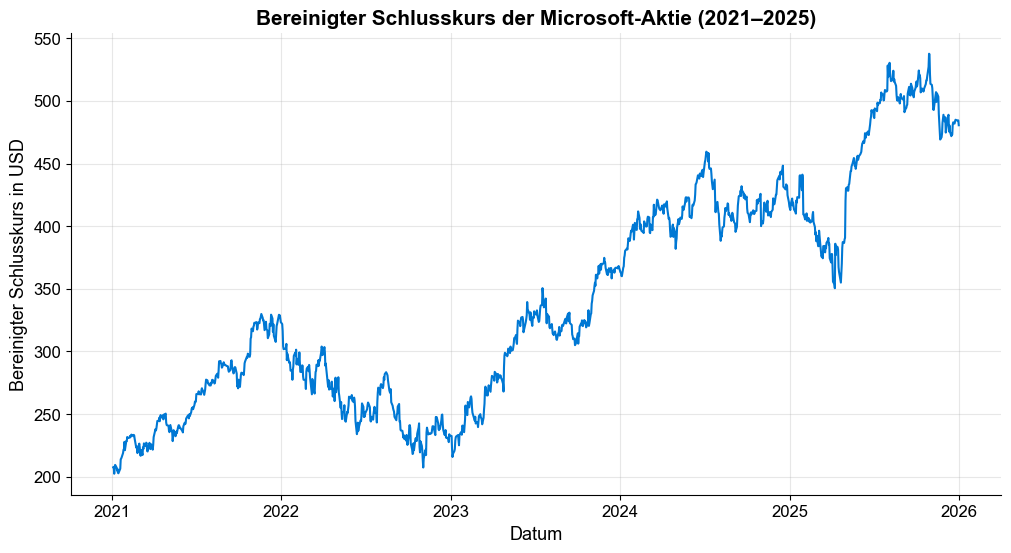

In [11]:
fig, ax = plt.subplots()
ax.plot(data.index, data["Close"], color=FARBEN["msft"], linewidth=1.5)
ax.set_title("Bereinigter Schlusskurs der Microsoft-Aktie (2021–2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Bereinigter Schlusskurs in USD")
plt.show()

### 3.1 Wichtige Kurswerte

Zusätzlich zur Grafik werden der erste, letzte, niedrigste und höchste bereinigte Schlusskurs des Untersuchungszeitraums ermittelt.

In [12]:
start_price = data["Close"].iloc[0] # iloc greift über die Position auf Werte zu.
end_price = data["Close"].iloc[-1]
lowest_price = data["Close"].min()
highest_price = data["Close"].max()

print("Bereinigter Schlusskurs zu Beginn:", round(start_price, 2), "USD")
print("Bereinigter Schlusskurs am Ende:", round(end_price, 2), "USD")
print("Niedrigster bereinigter Schlusskurs:", round(lowest_price, 2), "USD")
print("Höchster bereinigter Schlusskurs:", round(highest_price, 2), "USD")

Bereinigter Schlusskurs zu Beginn: 207.57 USD
Bereinigter Schlusskurs am Ende: 480.57 USD
Niedrigster bereinigter Schlusskurs: 202.38 USD
Höchster bereinigter Schlusskurs: 537.65 USD


Die Ausgabe zeigt den ersten und letzten sowie den niedrigsten und höchsten bereinigten Microsoft-Schlusskurs im Untersuchungszeitraum. Der letzte Wert liegt deutlich über dem ersten.

### 3.2 Wertveränderung im gesamten Zeitraum

Auf Basis des ersten und letzten bereinigten Schlusskurses wird die prozentuale Wertveränderung über den gesamten Untersuchungszeitraum berechnet. Dadurch lässt sich die Entwicklung in einer einzelnen Kennzahl zusammenfassen.

In [13]:
price_change = ((end_price - start_price) / start_price) * 100
print("Wertveränderung im gesamten Zeitraum:", round(price_change, 2), "%")

Wertveränderung im gesamten Zeitraum: 131.53 %


Der bereinigte Schlusskurs und damit die daraus abgeleitete Wertentwicklung steigen über den Untersuchungszeitraum deutlich. Die genaue prozentuale Veränderung ist in der vorstehenden Ausgabe angegeben.

### 3.3 Gleitende Durchschnitte (SMA 50 und SMA 200)

Gleitende Durchschnitte glätten kurzfristige Schwankungen und machen den Trend sichtbar. Verwendet werden der einfache gleitende Durchschnitt über 50 Handelstage (kurzfristiger Trend) und über 200 Handelstage (langfristiger Trend). Schneidet der SMA 50 den SMA 200 von unten, spricht man von einem *Golden Cross*, im umgekehrten Fall von einem *Death Cross*. Die Kreuzungen dienen hier nur zur Beschreibung von Trendphasen, nicht als Handelssignal.

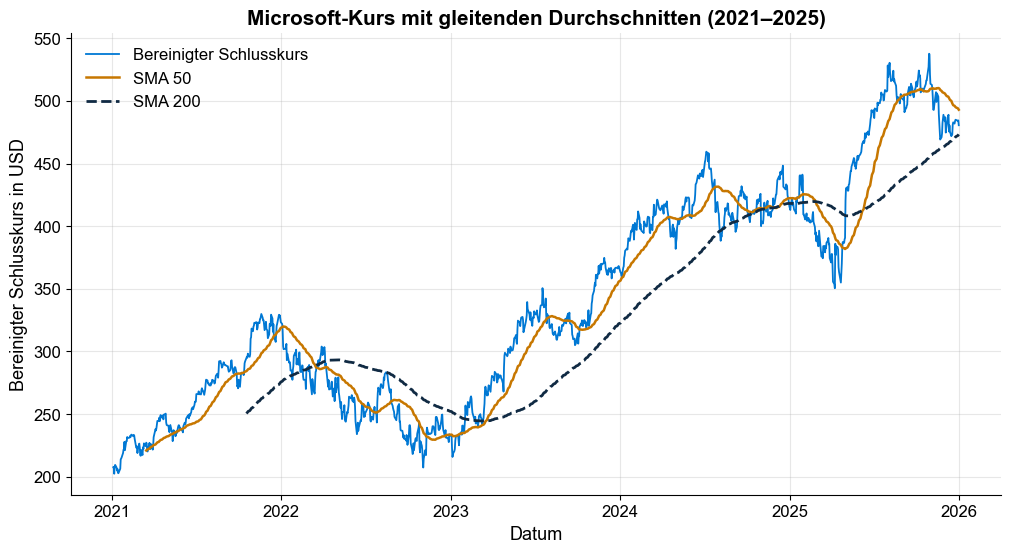

In [14]:
data["SMA_50"] = data["Close"].rolling(50).mean()    # Mittelwert der letzten 50 Handelstage
data["SMA_200"] = data["Close"].rolling(200).mean()  # Mittelwert der letzten 200 Handelstage

fig, ax = plt.subplots()
ax.plot(data.index, data["Close"], color=FARBEN["msft"], linewidth=1.3, label="Bereinigter Schlusskurs")
ax.plot(data.index, data["SMA_50"], color=FARBEN["markt"], linewidth=1.8, label="SMA 50")
ax.plot(data.index, data["SMA_200"], color=FARBEN["dunkel"], linewidth=2.0, linestyle="--", label="SMA 200")
ax.set_title("Microsoft-Kurs mit gleitenden Durchschnitten (2021–2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Bereinigter Schlusskurs in USD")
ax.legend(loc="upper left")
plt.show()

In [15]:
# Vorzeichen der Differenz: +1 = SMA 50 über SMA 200, -1 = darunter; ein Wechsel ist eine Kreuzung
signal = np.sign(data["SMA_50"] - data["SMA_200"])
crossings = signal.diff().dropna()
crossings = crossings[crossings != 0]

crossing_table = pd.DataFrame({
    "Datum": crossings.index.strftime("%d.%m.%Y"),
    "Ereignis": np.where(crossings > 0, "Golden Cross", "Death Cross"),
})

valid_sma = data["SMA_200"].notna()
share_above_sma200 = (data.loc[valid_sma, "Close"] > data.loc[valid_sma, "SMA_200"]).mean()

print("Anteil der Handelstage über dem SMA 200:", de(share_above_sma200 * 100, 1), "%")
crossing_table

Anteil der Handelstage über dem SMA 200: 68,5 %


,Datum,Ereignis
0,16.03.2022,Death Cross
1,20.03.2023,Golden Cross
2,29.11.2024,Death Cross
3,11.12.2024,Golden Cross
4,26.02.2025,Death Cross
5,09.06.2025,Golden Cross


Der Kurs lag an rund **68,5 %** der Handelstage (ab Verfügbarkeit des SMA 200) über seinem 200-Tage-Durchschnitt. Die längste Schwächephase reicht vom Death Cross im **März 2022** bis zum Golden Cross im **März 2023**. Danach folgen 2024 und 2025 nur kurze Unterbrechungen des Aufwärtstrends.

## 4. Renditeanalyse

Neben der Wertentwicklung ist die Rendite eine wichtige Kennzahl zur Beurteilung einer Aktie. Im folgenden Abschnitt werden die täglichen Renditen der Microsoft-Aktie berechnet und untersucht.

### 4.1 Tägliche Rendite

Die tägliche Rendite beschreibt die prozentuale Veränderung des bereinigten Schlusskurses gegenüber dem vorherigen Handelstag.

In [16]:
data["Return"] = data["Close"].pct_change() # pct_change() berechnet die relative Änderung gegenüber dem vorherigen Wert.
data[["Close", "Return"]].head()

,Close,Return
Date,,
2021-01-04 00:00:00-05:00,207.565353,NaN
2021-01-05 00:00:00-05:00,207.765579,0.000965
2021-01-06 00:00:00-05:00,202.378387,-0.025929
2021-01-07 00:00:00-05:00,208.137497,0.028457
2021-01-08 00:00:00-05:00,209.405609,0.006093


Für den ersten Handelstag kann keine Rendite berechnet werden, da im Datensatz kein vorheriger Schlusskurs vorhanden ist. Daher enthält die erste Zeile den Wert NaN.

### 4.2 Statistische Analyse der täglichen Renditen
Zur Untersuchung der täglichen Renditen werden grundlegende statistische Kennzahlen berechnet.
Die Ergebnisse werden auf vier Dezimalstellen gerundet, da tägliche Renditen häufig relativ kleine Werte aufweisen.

In [17]:
data["Return"].describe().round(4)

count    1254.0000
mean        0.0008
std         0.0162
min        -0.0772
25%        -0.0076
50%         0.0008
75%         0.0100
max         0.1013
Name: Return, dtype: float64

Zur besseren Interpretation der täglichen Renditen werden zusätzlich die durchschnittliche, die höchste und die niedrigste Tagesrendite berechnet. Die Werte werden in Prozent umgerechnet.

In [18]:
average_daily_return = data["Return"].mean() * 100
best_day = data["Return"].max() * 100
worst_day = data["Return"].min() * 100

print("Durchschnittliche tägliche Rendite:", round(average_daily_return, 3), "%")
print("Beste Tagesrendite:", round(best_day, 2), "%")
print("Schlechteste Tagesrendite:", round(worst_day, 2), "%")

Durchschnittliche tägliche Rendite: 0.08 %
Beste Tagesrendite: 10.13 %
Schlechteste Tagesrendite: -7.72 %


Die täglichen Veränderungen sind im Durchschnitt relativ klein.
Einzelne Handelstage können jedoch deutlich stärkere positive oder negative Ausschläge aufweisen.

### 4.3 Annualisierte durchschnittliche Rendite

Die durchschnittliche tägliche Rendite wird arithmetisch auf 252 Handelstage hochgerechnet. Die Kennzahl ist damit die **annualisierte durchschnittliche Rendite**, nicht die tatsächlich in jedem Kalenderjahr erzielte Rendite und nicht die geometrische Jahresrendite (CAGR).

In [19]:
trading_days = 252
annual_return = data["Return"].mean() * trading_days

print("Annualisierte durchschnittliche Rendite:", round(annual_return * 100, 2), "%")

Annualisierte durchschnittliche Rendite: 20.17 %


Die annualisierte durchschnittliche Rendite der Microsoft-Aktie ergibt sich aus der mittleren Tagesrendite mal 252. Sie ermöglicht einen Vergleich mit entsprechend berechneten Kennzahlen anderer Anlagen, bildet aber keine garantierte Jahresrendite ab.

### 4.4 Geometrische Jahresrendite (CAGR)

Die arithmetisch annualisierte Rendite überzeichnet das tatsächliche Wachstum, wenn die Renditen schwanken. Deshalb wird ergänzend die **Compound Annual Growth Rate (CAGR)** berechnet. Sie gibt an, mit welcher konstanten jährlichen Rate ein Anfangswert auf den Endwert gewachsen wäre:

$$CAGR = \left(\frac{K_{Ende}}{K_{Start}}\right)^{1/n} - 1, \qquad n = \frac{\text{Anzahl Tagesrenditen}}{252}$$

In [20]:
years = data["Return"].count() / trading_days  # Anzahl Jahre auf Basis der Tagesrenditen
cagr = (end_price / start_price) ** (1 / years) - 1

print("Betrachtete Jahre:", de(years, 2))
print("CAGR (geometrische Jahresrendite):", de(cagr * 100), "%")
print("Arithmetisch annualisierte Rendite:", de(annual_return * 100), "%")
print("Differenz:", de((annual_return - cagr) * 100), "Prozentpunkte")

Betrachtete Jahre: 4,98
CAGR (geometrische Jahresrendite): 18,38 %
Arithmetisch annualisierte Rendite: 20,17 %
Differenz: 1,79 Prozentpunkte


Die CAGR liegt mit rund **18,38 %** knapp **1,8 Prozentpunkte** unter der arithmetisch annualisierten Rendite von **20,17 %**. Die Differenz entsteht durch die Schwankungen: Ein Verlust muss durch einen prozentual größeren Gewinn ausgeglichen werden. Für die Frage „Wie stark ist eine Anlage tatsächlich pro Jahr gewachsen?“ ist die CAGR die aussagekräftigere Kennzahl.

### 4.5 Kumulative Rendite

Die kumulative Rendite zeigt die gesamte Wertentwicklung auf Basis der bereinigten Schlusskurse seit Beginn des Untersuchungszeitraums und berücksichtigt die Verkettung der täglichen Renditen.

In [21]:
# fillna(0) ersetzt fehlende Werte (NaN) durch 0
# cumprod() multipliziert die Werte schrittweise und berechnet das fortlaufende Produkt
data["Cumulative_Return"] = (1 + data["Return"].fillna(0)).cumprod() - 1
data[["Return", "Cumulative_Return"]].head()

,Return,Cumulative_Return
Date,,
2021-01-04 00:00:00-05:00,NaN,0.000000
2021-01-05 00:00:00-05:00,0.000965,0.000965
2021-01-06 00:00:00-05:00,-0.025929,-0.024990
2021-01-07 00:00:00-05:00,0.028457,0.002756
2021-01-08 00:00:00-05:00,0.006093,0.008866


### 4.6 Entwicklung der kumulativen Rendite

Die kumulative Rendite wird über den gesamten Zeitraum visualisiert. Die Grafik zeigt, wann besonders starke Zuwächse und Rückgänge auftraten.

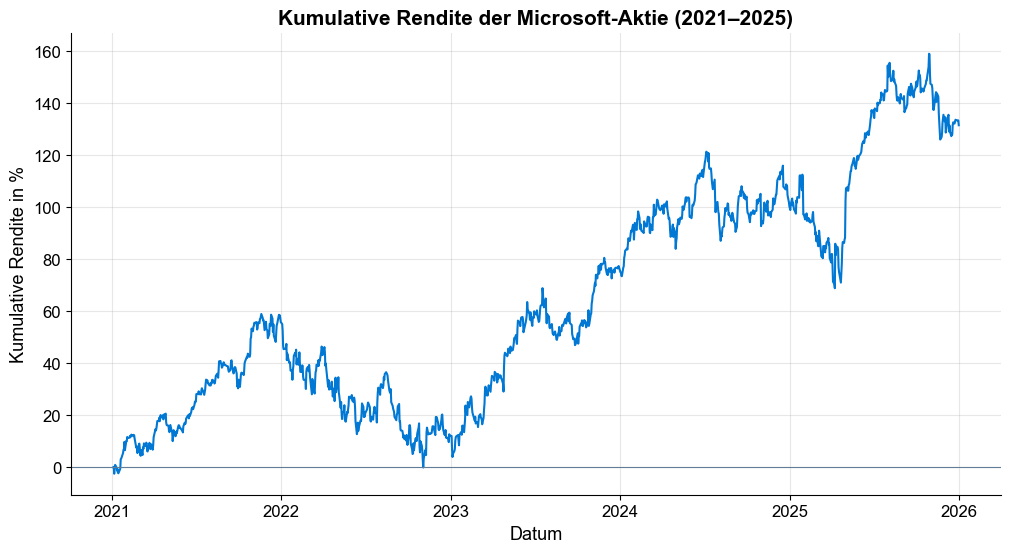

In [22]:
fig, ax = plt.subplots()
ax.plot(data.index, data["Cumulative_Return"] * 100, color=FARBEN["msft"], linewidth=1.5)
ax.axhline(0, color=FARBEN["grau"], linewidth=0.8)
ax.set_title("Kumulative Rendite der Microsoft-Aktie (2021–2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Kumulative Rendite in %")
plt.show()

In [23]:
final_cumulative_return = data["Cumulative_Return"].iloc[-1] * 100

print("Kumulative Rendite am Ende des Zeitraums:", round(final_cumulative_return, 2), "%")    

Kumulative Rendite am Ende des Zeitraums: 131.53 %


Die kumulative Rendite am Ende des Untersuchungszeitraums entspricht der aus erstem und letztem bereinigtem Schlusskurs berechneten Wertveränderung. Eine hypothetische Anlage hätte ihren Wert auf dieser Berechnungsbasis mehr als verdoppelt; Steuern und Transaktionskosten sind dabei nicht berücksichtigt.

### 4.7 Verteilung der Tagesrenditen

Viele Risikokennzahlen (z. B. die Volatilität als alleiniges Risikomaß) sind besonders aussagekräftig, wenn die Renditen annähernd normalverteilt sind. Daher werden **Schiefe**, **Exzess-Kurtosis** und der **Jarque-Bera-Test** (Jarque & Bera, 1980) berechnet. Eine Normalverteilung hat eine Schiefe und eine Exzess-Kurtosis von 0. Ein Histogramm vergleicht die tatsächliche Verteilung mit einer Normalverteilung mit gleichem Mittelwert und gleicher Standardabweichung.

In [24]:
daily_returns = data["Return"].dropna()

skewness = stats.skew(daily_returns)
excess_kurtosis = stats.kurtosis(daily_returns)  # Exzess-Kurtosis: Normalverteilung = 0
jb_stat, jb_p = stats.jarque_bera(daily_returns)

print("Schiefe:", de(skewness, 3))
print("Exzess-Kurtosis:", de(excess_kurtosis, 3))
print("Jarque-Bera-Statistik:", de(jb_stat, 1), "| p-Wert:", f"{jb_p:.2e}")

Schiefe: 0,205
Exzess-Kurtosis: 3,225
Jarque-Bera-Statistik: 552,3 | p-Wert: 1.18e-120


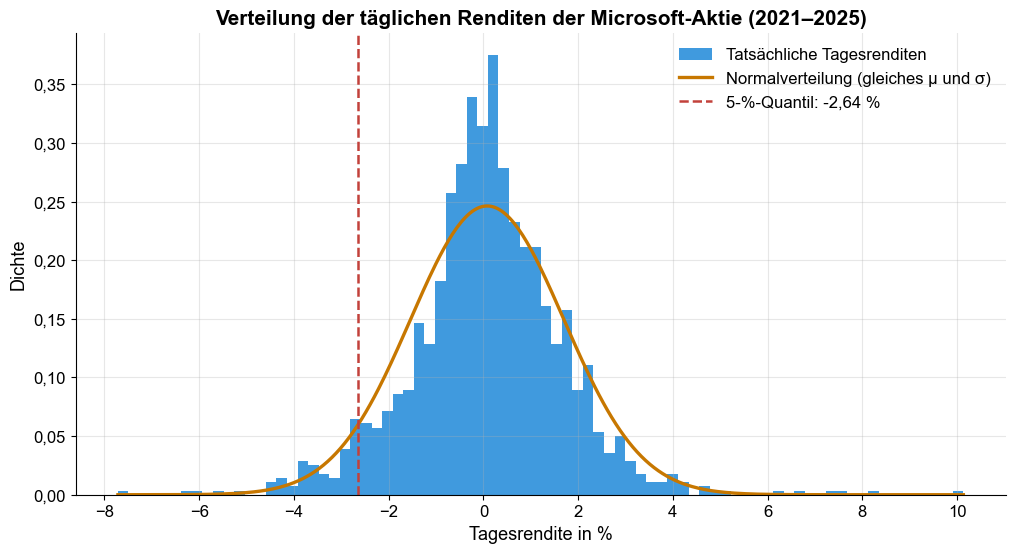

In [25]:
returns_pct = daily_returns * 100
mu, sigma = returns_pct.mean(), returns_pct.std()
quantile_5 = returns_pct.quantile(0.05)

fig, ax = plt.subplots()
ax.hist(returns_pct, bins=80, density=True, color=FARBEN["msft"], alpha=0.75, label="Tatsächliche Tagesrenditen")
x = np.linspace(returns_pct.min(), returns_pct.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sigma), color=FARBEN["markt"], linewidth=2.4, label="Normalverteilung (gleiches μ und σ)")
ax.axvline(quantile_5, color=FARBEN["negativ"], linestyle="--", linewidth=1.8, label=f"5-%-Quantil: {de(quantile_5)} %")
ax.set_title("Verteilung der täglichen Renditen der Microsoft-Aktie (2021–2025)")
ax.set_xticks(range(-8, 11, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: de(v, 2)))
ax.set_xlabel("Tagesrendite in %")
ax.set_ylabel("Dichte")
ax.legend(loc="upper right")
plt.show()

Die Verteilung ist leicht rechtsschief (Schiefe ≈ **0,21**) und deutlich spitzer mit breiteren Rändern als eine Normalverteilung (Exzess-Kurtosis ≈ **3,23**). Der Jarque-Bera-Test lehnt die Normalverteilungsannahme klar ab (p < 0,001). Extreme Tagesbewegungen wie **−7,72 %** oder **+10,13 %** treten damit häufiger auf, als eine Normalverteilung erwarten ließe. Die Volatilität allein unterschätzt daher das Risiko seltener, starker Verluste; deshalb werden in Abschnitt 5.6 zusätzlich Value at Risk und Conditional Value at Risk berechnet.

## 5. Risikoanalyse

Das Risiko der Microsoft-Aktie wird anhand von Volatilität, rollierender Volatilität und Maximum Drawdown untersucht.

### 5.1 Volatilität
Die Volatilität beschreibt, wie stark die Renditen einer Aktie schwanken. Eine höhere Volatilität bedeutet stärkere Schwankungen der Renditen und weist grundsätzlich auf ein höheres Schwankungsrisiko hin.  
Zur Berechnung der täglichen Volatilität wird die Standardabweichung der täglichen Renditen verwendet. Anschließend wird die tägliche Volatilität auf Jahresbasis hochgerechnet.

In [26]:
daily_volatility = data["Return"].std()
annual_volatility = daily_volatility * np.sqrt(252) # np.sqrt() berechnet die Quadratwurzel eines Wertes

print("Tägliche Volatilität:", round(daily_volatility * 100, 2),"%")
print("Annualisierte Volatilität:", round(annual_volatility * 100, 2),"%")    

Tägliche Volatilität: 1.62 %
Annualisierte Volatilität: 25.71 %


Die Kennzahlen der Volatilität zeigen, dass die Renditen der Aktie im Untersuchungszeitraum deutlichen Schwankungen unterlagen.

### 5.2 Maximum Drawdown
Der Maximum Drawdown zeigt den größten prozentualen Verlust von einem zuvor erreichten Höchststand bis zu einem späteren Tiefpunkt.
Diese Kennzahl ist hilfreich, um zu beurteilen, welchen maximalen zwischenzeitlichen Verlust eine Investition innerhalb des untersuchten Zeitraums erfahren hätte.

In [27]:
wealth_index = (1 + data["Return"].fillna(0)).cumprod()
running_max = wealth_index.cummax() # cummax() gibt für jede Position den bisher höchsten erreichten Wert zurück

data["Drawdown"] = wealth_index / running_max - 1
max_drawdown = data["Drawdown"].min()

print("Maximum Drawdown:", round(max_drawdown * 100, 2), "%")    

max_drawdown_date = data["Drawdown"].idxmin() # idxmin() gibt den Index des kleinsten Wertes zurück

print("Datum des Maximum Drawdown:", max_drawdown_date.date())    

Maximum Drawdown: -37.15 %
Datum des Maximum Drawdown: 2022-11-03


Der Maximum Drawdown der Microsoft-Aktie beträgt rund −37,15 %. Der stärkste Rückgang gegenüber einem zuvor erreichten Höchststand wurde am 03.11.2022 erreicht.

### 5.3 Entwicklung des Drawdowns
Die Drawdown-Grafik zeigt mehrere deutliche Rückgangsphasen. Damit wird sichtbar, dass eine langfristig positive Wertentwicklung dennoch mit erheblichen zwischenzeitlichen Verlusten verbunden sein kann.

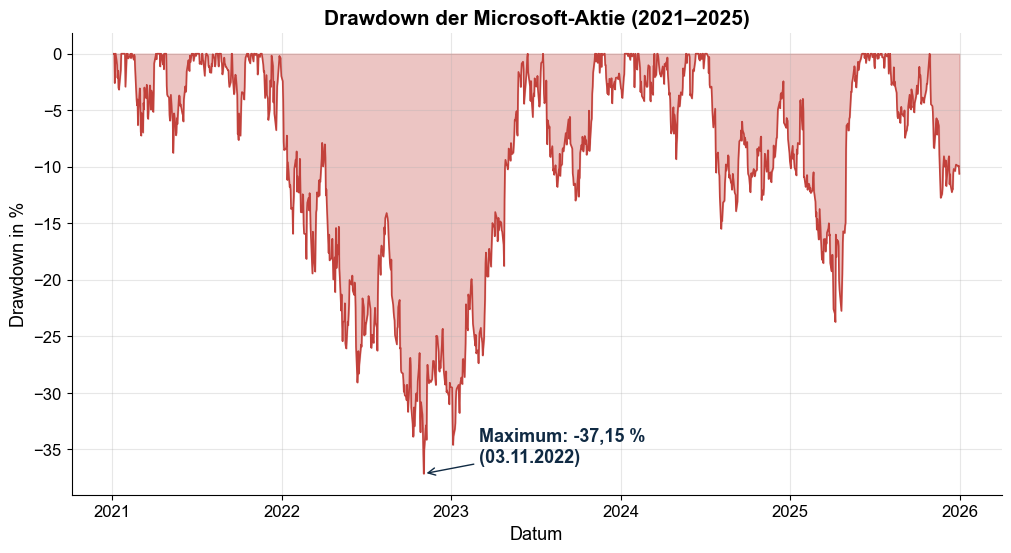

In [28]:
fig, ax = plt.subplots()
ax.fill_between(data.index, data["Drawdown"] * 100, 0, color=FARBEN["negativ"], alpha=0.30)
ax.plot(data.index, data["Drawdown"] * 100, color=FARBEN["negativ"], linewidth=1.2)
ax.annotate(f"Maximum: {de(max_drawdown * 100)} %\n({max_drawdown_date:%d.%m.%Y})",
            xy=(max_drawdown_date, max_drawdown * 100), xytext=(40, 8), textcoords="offset points",
            color=FARBEN["dunkel"], fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=FARBEN["dunkel"]))
ax.set_title("Drawdown der Microsoft-Aktie (2021–2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Drawdown in %")
plt.show()

Die Drawdown-Grafik zeigt, dass die Microsoft-Aktie trotz ihrer langfristig positiven Entwicklung mehrere deutliche Rückgangsphasen aufweist. Dies verdeutlicht, dass eine positive langfristige Rendite nicht bedeutet, dass eine Investition während des gesamten Zeitraums ohne größere zwischenzeitliche Verluste verläuft.

### 5.4 Entwicklung der Volatilität

Da das Schwankungsrisiko einer Aktie im Zeitverlauf nicht konstant ist, wird zusätzlich die rollierende Volatilität über jeweils 30 **Handelstage** berechnet. Das Fenster von 30 Handelstagen dient als kurzfristiger Betrachtungszeitraum, um Veränderungen der Volatilität im Zeitverlauf sichtbar zu machen.

Die 30-Tage-Standardabweichung wird mit der Wurzel aus 252 annualisiert, um die Werte mit der Gesamtvolatilität vergleichen zu können. Zu Beginn des Zeitraums fehlen die für ein vollständiges Fenster erforderlichen Beobachtungen.

In [29]:
# rolling(30) bildet ein gleitendes Fenster aus 30 aufeinanderfolgenden Handelstagen.
data["Rolling_Volatility"] = data["Return"].rolling(30).std() * np.sqrt(trading_days) * 100

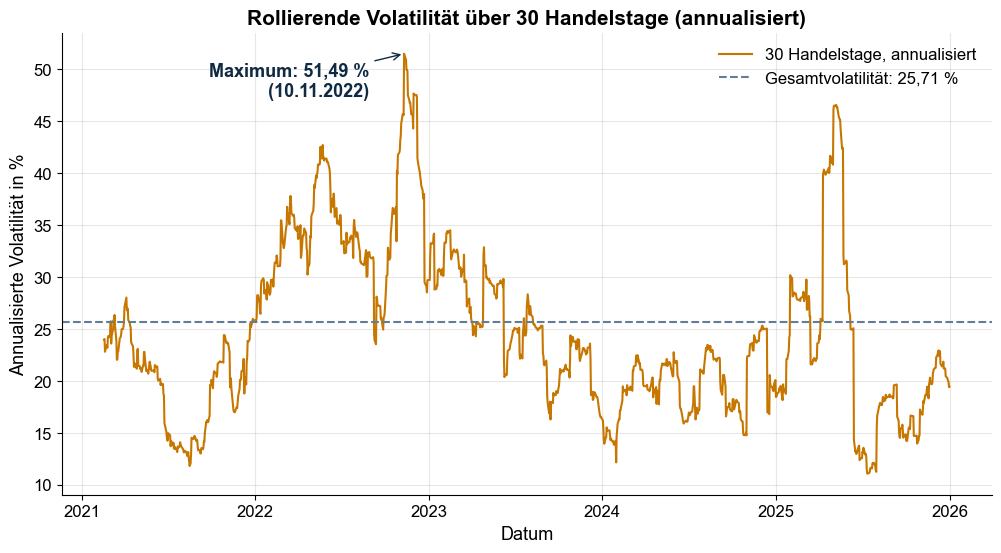

In [30]:
vol_peak_date = data["Rolling_Volatility"].idxmax()
vol_peak = data["Rolling_Volatility"].max()

fig, ax = plt.subplots()
ax.plot(data.index, data["Rolling_Volatility"], color=FARBEN["markt"], linewidth=1.5, label="30 Handelstage, annualisiert")
ax.axhline(annual_volatility * 100, color=FARBEN["grau"], linestyle="--", linewidth=1.5,
           label=f"Gesamtvolatilität: {de(annual_volatility * 100)} %")
ax.annotate(f"Maximum: {de(vol_peak)} %\n({vol_peak_date:%d.%m.%Y})",
            xy=(vol_peak_date, vol_peak), xytext=(-25, -6), textcoords="offset points", ha="right", va="top",
            color=FARBEN["dunkel"], fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=FARBEN["dunkel"]))
ax.set_title("Rollierende Volatilität über 30 Handelstage (annualisiert)")
ax.set_xlabel("Datum")
ax.set_ylabel("Annualisierte Volatilität in %")
ax.legend(loc="upper right")
plt.show()

Die Grafik zeigt, dass die Volatilität im Untersuchungszeitraum nicht konstant ist. In einzelnen Phasen treten deutlich stärkere Schwankungen auf als in anderen. Damit ergänzt die rollierende Volatilität die bisherige Risikoanalyse um eine zeitliche Perspektive.

In [31]:
average_volatility = data["Rolling_Volatility"].mean()
maximum_volatility = data["Rolling_Volatility"].max()
maximum_volatility_date = data["Rolling_Volatility"].idxmax() # idxmax() gibt den Index des größten Wertes zurück.

print("Durchschnittliche annualisierte 30-Handelstage-Volatilität:", round(average_volatility, 2), "%")
print("Maximale annualisierte 30-Handelstage-Volatilität:", round(maximum_volatility, 2), "%")
print("Datum der maximalen Volatilität:", maximum_volatility_date.date())

Durchschnittliche annualisierte 30-Handelstage-Volatilität: 24.6 %
Maximale annualisierte 30-Handelstage-Volatilität: 51.49 %
Datum der maximalen Volatilität: 2022-11-10


### 5.5 Interpretation der Volatilität

Die durchschnittliche annualisierte Volatilität der rollierenden 30-Handelstage-Fenster liegt im Untersuchungszeitraum bei rund **24,60 %**. Das Maximum von rund **51,49 %** tritt am **10. November 2022** auf. Die Werte zeigen, dass das Schwankungsrisiko im Zeitverlauf variiert. Der Durchschnitt der rollierenden Werte ist nicht identisch mit der aus allen Tagesrenditen berechneten annualisierten Gesamtvolatilität.

### 5.6 Value at Risk und Conditional Value at Risk

Da die Tagesrenditen nicht normalverteilt sind (Abschnitt 4.7), wird das Verlustrisiko zusätzlich über Quantile beschrieben (Jorion, 2007):

- **Value at Risk (VaR 95 %, 1 Tag):** Verlust, der an 95 % der Handelstage nicht überschritten wurde.
- **Conditional Value at Risk (CVaR 95 %):** durchschnittlicher Verlust an den 5 % schlechtesten Tagen.

Der historische VaR verwendet direkt das empirische 5-%-Quantil. Zum Vergleich wird der parametrische VaR unter Normalverteilungsannahme berechnet.

In [32]:
var_95_hist = -daily_returns.quantile(0.05)
cvar_95 = -daily_returns[daily_returns <= daily_returns.quantile(0.05)].mean()
var_95_param = -(daily_returns.mean() + stats.norm.ppf(0.05) * daily_returns.std())

print("Historischer VaR (95 %, 1 Tag):", de(var_95_hist * 100), "%")
print("Parametrischer VaR (95 %, 1 Tag):", de(var_95_param * 100), "%")
print("Conditional VaR (95 %, 1 Tag):", de(cvar_95 * 100), "%")

Historischer VaR (95 %, 1 Tag): 2,64 %
Parametrischer VaR (95 %, 1 Tag): 2,58 %
Conditional VaR (95 %, 1 Tag): 3,55 %


An 95 % der Handelstage verlor die Aktie höchstens rund **2,64 %**. Wenn dieser Wert überschritten wurde, betrug der Verlust im Durchschnitt rund **3,55 %** (CVaR). Der parametrische VaR liegt mit **2,58 %** nahe am historischen Wert; die Abweichung von der Normalverteilung zeigt sich vor allem in den extremen Rändern, die der CVaR besser erfasst.

## 6. Bewertung der Aktie – Risiko und Rendite

Nachdem Rendite, Drawdown und Volatilität einzeln untersucht wurden, werden die wichtigsten Kennzahlen gemeinsam betrachtet. Dazu dienen:

- annualisierte durchschnittliche Rendite und CAGR
- annualisierte Volatilität
- Maximum Drawdown
- Value at Risk
- Sharpe Ratio und Sortino Ratio

### 6.1 Annualisierte durchschnittliche Rendite

In [33]:
annualized_return = data["Return"].mean() * trading_days

print("Annualisierte durchschnittliche Rendite:", round(annualized_return * 100, 2), "%")

Annualisierte durchschnittliche Rendite: 20.17 %


Die annualisierte durchschnittliche Rendite ergibt sich aus dem arithmetischen Mittel der Tagesrenditen mal 252. Sie sollte nicht isoliert betrachtet werden, da eine höhere Rendite mit einem höheren Risiko verbunden sein kann.

### 6.2 Risikofreier Zinssatz und Sharpe Ratio

Die Sharpe Ratio (Sharpe, 1966) setzt die Überrendite gegenüber einer risikofreien Anlage ins Verhältnis zur Volatilität. Im Zeitraum 2021–2025 schwankten die US-Geldmarktzinsen stark (nahe 0 % bis über 5 %). Ein pauschaler Zinssatz von 0 % würde die Sharpe Ratio daher überzeichnen. Als risikofreier Zinssatz wird deshalb die annualisierte Rendite 13-wöchiger US-Schatzwechsel (`^IRX`) verwendet. Die Tageswerte werden den Handelstagen der Aktie zugeordnet; fehlende Tage werden mit dem letzten verfügbaren Wert gefüllt.

In [34]:
irx = yf.download("^IRX", start="2021-01-01", end="2026-01-01", auto_adjust=True, progress=False)

if irx.empty:
    raise ValueError("Keine Zinsdaten (^IRX) geladen.")

if isinstance(irx.columns, pd.MultiIndex):
    irx.columns = irx.columns.get_level_values(0)

irx_rate = irx["Close"] / 100  # ^IRX wird in Prozent angegeben
irx_rate.index = pd.to_datetime(irx_rate.index)
if irx_rate.index.tz is not None:
    irx_rate.index = irx_rate.index.tz_localize(None)

return_dates = daily_returns.index.tz_localize(None) if daily_returns.index.tz is not None else daily_returns.index
rf_annual_series = irx_rate.reindex(return_dates).ffill()

annualized_volatility = data["Return"].std() * np.sqrt(trading_days)
risk_free_rate = rf_annual_series.mean()  # durchschnittlicher risikofreier Zinssatz p. a.

sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility
sharpe_ratio_rf0 = annualized_return / annualized_volatility  # Robustheitsprüfung mit rf = 0 %

print("Durchschnittlicher risikofreier Zinssatz (^IRX):", de(risk_free_rate * 100), "%")
print("Annualisierte durchschnittliche Rendite:", de(annualized_return * 100), "%")
print("Annualisierte Volatilität:", de(annualized_volatility * 100), "%")
print("Sharpe Ratio (rf = ^IRX):", de(sharpe_ratio))
print("Sharpe Ratio (rf = 0 %, Robustheitsprüfung):", de(sharpe_ratio_rf0))

Durchschnittlicher risikofreier Zinssatz (^IRX): 3,22 %
Annualisierte durchschnittliche Rendite: 20,17 %
Annualisierte Volatilität: 25,71 %
Sharpe Ratio (rf = ^IRX): 0,66
Sharpe Ratio (rf = 0 %, Robustheitsprüfung): 0,78


Bei einem durchschnittlichen risikofreien Zinssatz von rund **3,22 %** ergibt sich eine Sharpe Ratio von rund **0,66**. Mit einem Zinssatz von 0 % wären es **0,78**. Ein höherer Wert bedeutet eine höhere Überrendite je Einheit des gemessenen Schwankungsrisikos; andere Risikoarten werden dadurch nicht erfasst.

### 6.3 Sortino Ratio

Die Volatilität bewertet positive und negative Abweichungen gleich. Die **Sortino Ratio** (Sortino & van der Meer, 1991) berücksichtigt dagegen nur die Abwärtsschwankungen: Die Überrendite wird durch die annualisierte *Downside Deviation* geteilt, also die Streuung der negativen Überrenditen.

In [35]:
def sortino_ratio(returns, rf_annual, days=trading_days):
    """Sortino Ratio auf Basis täglicher Renditen und eines täglichen risikofreien Zinssatzes."""
    excess = returns - rf_annual / days
    downside_deviation = np.sqrt((np.minimum(excess, 0) ** 2).mean()) * np.sqrt(days)
    return excess.mean() * days / downside_deviation

msft_sortino = sortino_ratio(daily_returns.values, rf_annual_series.values)
print("Sortino Ratio Microsoft (rf = ^IRX):", de(msft_sortino))

Sortino Ratio Microsoft (rf = ^IRX): 0,97


Die Sortino Ratio von rund **0,97** liegt über der Sharpe Ratio, weil ein Teil der Schwankungen auf positive Tagesrenditen entfällt. Der Vergleich mit dem Markt folgt in Abschnitt 6.6.

### 6.4 Zusammenfassung der Risiko-Rendite-Kennzahlen

In [36]:
summary = {
    "Kennzahl": [
        "Annualisierte durchschnittliche Rendite (arithmetisch)",
        "CAGR (geometrische Jahresrendite)",
        "Annualisierte Volatilität",
        "Durchschnittliche annualisierte 30-Handelstage-Volatilität",
        "Maximale annualisierte 30-Handelstage-Volatilität",
        "Maximum Drawdown",
        "Value at Risk (95 %, 1 Tag, historisch)",
        "Conditional VaR (95 %, 1 Tag)",
        "Sharpe Ratio (rf = ^IRX)",
        "Sharpe Ratio (rf = 0 %)",
        "Sortino Ratio (rf = ^IRX)",
    ],
    "Wert": [
        f"{de(annualized_return * 100)} %",
        f"{de(cagr * 100)} %",
        f"{de(annualized_volatility * 100)} %",
        f"{de(average_volatility)} %",
        f"{de(maximum_volatility)} %",
        f"{de(max_drawdown * 100)} %",
        f"{de(-var_95_hist * 100)} %",
        f"{de(-cvar_95 * 100)} %",
        de(sharpe_ratio),
        de(sharpe_ratio_rf0),
        de(msft_sortino),
    ]
}
summary_df = pd.DataFrame(summary)
summary_df

,Kennzahl,Wert
0,Annualisierte durchschnittliche Rendite (arith...,"20,17 %"
1,CAGR (geometrische Jahresrendite),"18,38 %"
2,Annualisierte Volatilität,"25,71 %"
3,Durchschnittliche annualisierte 30-Handelstage...,"24,60 %"
4,Maximale annualisierte 30-Handelstage-Volatilität,"51,49 %"
5,Maximum Drawdown,"-37,15 %"
6,"Value at Risk (95 %, 1 Tag, historisch)","-2,64 %"
7,"Conditional VaR (95 %, 1 Tag)","-3,55 %"
8,Sharpe Ratio (rf = ^IRX),"0,66"
9,Sharpe Ratio (rf = 0 %),"0,78"


Die Tabelle fasst die Rendite- und Risikokennzahlen der Microsoft-Aktie zusammen. Die Rendite ist arithmetisch wie geometrisch deutlich positiv, während Volatilität, Maximum Drawdown und VaR auf erhebliche Schwankungen und zwischenzeitliche Verluste hinweisen. Die Sharpe Ratio ist mit dem tatsächlichen risikofreien Zinssatz (`^IRX`) spürbar niedriger als mit 0 %.

### 6.5 Gesamtbewertung des Risiko-Rendite-Profils

Eine höhere Rendite allein belegt noch kein günstigeres Risiko-Rendite-Profil. Deshalb werden die Microsoft-Kennzahlen im nächsten Schritt denen des S&P 500 gegenübergestellt und anschließend gemeinsam in einem Risiko-Rendite-Diagramm gezeigt.

### 6.6 Benchmark-Analyse: Microsoft vs. S&P 500

Der S&P 500 dient als Benchmark für die Einordnung der Microsoft-Aktie. Für eine möglichst einheitliche Ertragsbasis wird der **S&P 500 Total Return Index** verwendet; sein Yahoo-Finance-Ticker ist `^SP500TR`. Dieser Index berücksichtigt Dividenden. Er ist daher für die bereinigte Microsoft-Kursreihe geeigneter als der reine S&P-500-Preisindex `^GSPC`.

Für beide Reihen gilt derselbe Untersuchungszeitraum von 2021 bis 2025. Die Daten werden anhand gemeinsamer Handelstage zusammengeführt.

#### 6.6.1 Laden der Benchmark-Daten

Die historischen Kursdaten des S&P 500 Total Return Index (`^SP500TR`) werden für denselben Untersuchungszeitraum wie die Microsoft-Daten geladen.

In [37]:
start_date = data.index.min()
end_date = data.index.max()

if start_date.tzinfo is not None:
    start_date = start_date.tz_localize(None) # tz_localize(None) entfernt die Zeitzoneninformation eines Datums.

if end_date.tzinfo is not None:
    end_date = end_date.tz_localize(None)

end_date = end_date + pd.Timedelta(days=1) # Timedelta beschreibt eine Zeitspanne.

sp500 = yf.download(
    "^SP500TR",
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

if sp500.empty:
    raise ValueError("Keine S&P-500-Total-Return-Daten geladen.")

print("Abrufdatum der Benchmark-Daten:", pd.Timestamp.now().strftime("%d.%m.%Y"))
sp500.head()

Abrufdatum der Benchmark-Daten: 20.10.2026


Price,Close,High,Low,Open,Volume
Ticker,^SP500TR,^SP500TR,^SP500TR,^SP500TR,^SP500TR
Date,,,,,
2021-01-04,7645.270020,7788.350098,7567.080078,7777.410156,0
2021-01-05,7700.339844,7722.689941,7635.640137,7640.770020,0
2021-01-06,7744.430176,7744.430176,7744.430176,7744.430176,0
2021-01-07,7861.100098,7876.669922,7780.350098,7780.350098,0
2021-01-08,7905.279785,7909.319824,7820.379883,7885.359863,0


#### 6.6.2 Kontrolle der geladenen Daten

Vor der weiteren Analyse werden Spalten, Zeitraum und Umfang des Benchmark-Datensatzes geprüft.

In [38]:
print(sp500.columns)

print()

print("Erstes Datum:", sp500.index.min())
print("Letztes Datum:", sp500.index.max())

print()

print(sp500.shape)

MultiIndex([( 'Close', '^SP500TR'),
            (  'High', '^SP500TR'),
            (   'Low', '^SP500TR'),
            (  'Open', '^SP500TR'),
            ('Volume', '^SP500TR')],
           names=['Price', 'Ticker'])

Erstes Datum: 2021-01-04 00:00:00
Letztes Datum: 2025-12-31 00:00:00

(1255, 5)


#### 6.6.3 Vereinheitlichung der Datenstruktur

Abhängig von der verwendeten `yfinance`-Version können die geladenen Benchmark-Daten einen MultiIndex besitzen. Für die weitere Analyse wird in diesem Fall die erste Ebene der Spaltenbezeichnungen übernommen.

In [39]:
# isinstance() prüft, ob ein Objekt einem bestimmten Datentyp entspricht
if isinstance(sp500.columns, pd.MultiIndex):
    
    # get_level_values(0) gibt die Werte der ersten Ebene eines MultiIndex zurück
    sp500.columns = sp500.columns.get_level_values(0)
    
sp500.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2021-01-04,7645.270020,7788.350098,7567.080078,7777.410156,0
2021-01-05,7700.339844,7722.689941,7635.640137,7640.770020,0
2021-01-06,7744.430176,7744.430176,7744.430176,7744.430176,0
2021-01-07,7861.100098,7876.669922,7780.350098,7780.350098,0
2021-01-08,7905.279785,7909.319824,7820.379883,7885.359863,0


#### 6.6.4 Vereinheitlichung der Zeitindizes

Die Microsoft- und Benchmark-Daten können unterschiedliche Zeitzoneninformationen enthalten. Für den täglichen Vergleich werden beide Indizes in ein Datumsformat umgewandelt und mögliche Zeitzoneninformationen entfernt. Dadurch lassen sich die Zeitreihen anhand ihrer Handelstage zusammenführen.

In [40]:
data.index = pd.to_datetime(data.index) # to_datetime() wandelt Werte in ein Datums- und Zeitformat um
sp500.index = pd.to_datetime(sp500.index)

if data.index.tz is not None:
    data.index = data.index.tz_localize(None)

if sp500.index.tz is not None:
    sp500.index = sp500.index.tz_localize(None)

print("Microsoft timezone:", data.index.tz)
print("S&P 500 timezone:", sp500.index.tz)

Microsoft timezone: None
S&P 500 timezone: None


#### 6.6.5 Auswahl der Schlusskurse

Für den Vergleich werden die bereinigten Microsoft-Schlusskurse und die Indexstände des S&P 500 Total Return ausgewählt. Beide Reihen werden als eindimensionale Series bereitgestellt.

In [41]:
msft_close = data["Close"].copy() # copy() erstellt eine unabhängige Kopie eines Objekts

if isinstance(msft_close, pd.DataFrame):
    msft_close = msft_close.iloc[:, 0]

sp500_close = sp500["Close"].copy()

if isinstance(sp500_close, pd.DataFrame):
    sp500_close = sp500_close.iloc[:, 0]

print(type(msft_close))
print(type(sp500_close))

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


#### 6.6.6 Zusammenführung der Zeitreihen

Die beiden Reihen werden nach Handelstag zu einem gemeinsamen DataFrame zusammengeführt. Berücksichtigt werden nur Tage mit Werten in beiden Reihen; eventuell fehlende Werte werden entfernt. Damit beruhen beide Kennzahlensätze auf derselben Beobachtungsbasis.

In [42]:
# concat() verbindet Pandas-Objekte zu einem gemeinsamen Objekt.
comparison = pd.concat( 
    [msft_close.rename("Microsoft"),
     sp500_close.rename("S&P 500 (Total Return)")],
    axis=1,
    join="inner" # join="inner" übernimmt nur in beiden Reihen vorhandene Handelstage.
).dropna() # dropna() entfernt Zeilen mit fehlenden Werten.

comparison.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-04,207.565353,7645.270020
2021-01-05,207.765579,7700.339844
2021-01-06,202.378387,7744.430176
2021-01-07,208.137497,7861.100098
2021-01-08,209.405609,7905.279785


In [43]:
comparison.tail()

,Microsoft,S&P 500 (Total Return)
Date,,
2025-12-24,484.943420,15409.700195
2025-12-26,484.635406,15406.480469
2025-12-29,484.029236,15353.160156
2025-12-30,484.406860,15332.070312
2025-12-31,480.571167,15220.450195


In [44]:
print("Anzahl gemeinsamer Handelstage:", len(comparison))
print("Beginn:", comparison.index.min().date())
print("Ende:", comparison.index.max().date())

Anzahl gemeinsamer Handelstage: 1255
Beginn: 2021-01-04
Ende: 2025-12-31


Nach der Zusammenführung umfasst der gemeinsame Datensatz **1.255 Handelstage** vom **04.01.2021** bis zum **31.12.2025**. Damit stehen für Microsoft und den S&P 500 über den gesamten Untersuchungszeitraum vergleichbare Beobachtungen zur Verfügung.

#### 6.6.7 Vergleich der Wertentwicklung

Die absoluten Kurs- und Indexniveaus sind nicht direkt vergleichbar. Beide Reihen werden deshalb auf einen gemeinsamen Startwert von **100** normiert. Ein Wert von 150 entspricht einer Wertsteigerung von 50 % seit dem gemeinsamen Startdatum.

In [45]:
# div() dividiert Werte elementweise durch andere Werte
# mul() multipliziert Werte elementweise mit einem angegebenen Wert
normalized = comparison.div(comparison.iloc[0]).mul(100)
normalized.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-04,100.000000,100.000000
2021-01-05,100.096464,100.720312
2021-01-06,97.501044,101.297013
2021-01-07,100.275645,102.823054
2021-01-08,100.886591,103.400923


##### Grafischer Vergleich

Die normierten Wertentwicklungen von Microsoft und dem S&P 500 Total Return werden gemeinsam dargestellt. Die horizontale Linie bei 100 kennzeichnet den Ausgangswert.

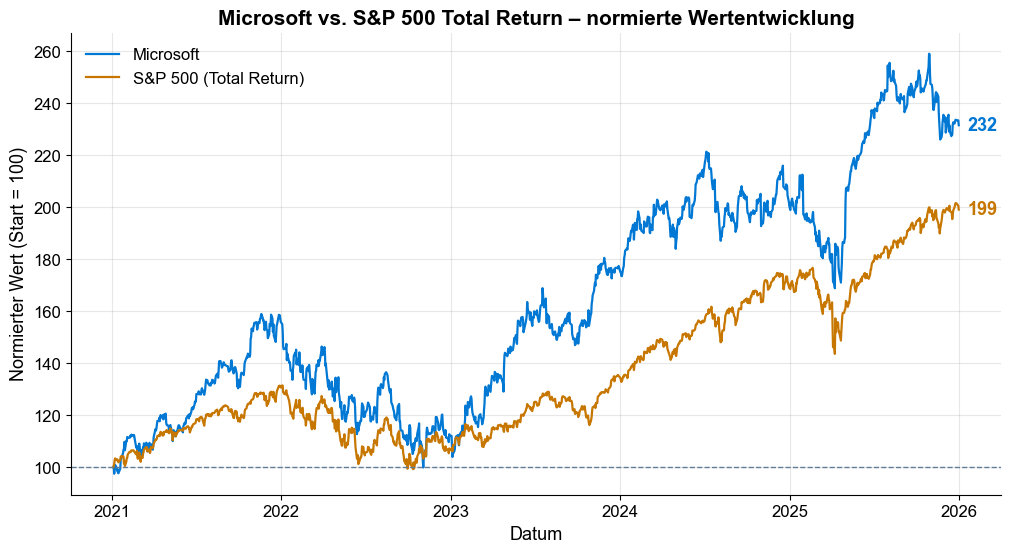

In [46]:
fig, ax = plt.subplots()
for column, color in [("Microsoft", FARBEN["msft"]), ("S&P 500 (Total Return)", FARBEN["markt"])]:
    ax.plot(normalized.index, normalized[column], color=color, linewidth=1.6, label=column)
    end_value = normalized[column].iloc[-1]
    ax.annotate(de(end_value, 0), xy=(normalized.index[-1], end_value), xytext=(6, 0),
                textcoords="offset points", va="center", color=color, fontweight="bold")
ax.axhline(100, color=FARBEN["grau"], linestyle="--", linewidth=1)  # Ausgangswert
ax.set_title("Microsoft vs. S&P 500 Total Return – normierte Wertentwicklung")
ax.set_xlabel("Datum")
ax.set_ylabel("Normierter Wert (Start = 100)")
ax.legend(loc="upper left")
plt.show()

#### 6.6.8 Tägliche Renditen

Für die weitere Benchmark-Analyse werden aus den gemeinsamen Werten die täglichen Renditen beider Reihen berechnet. Die erste Beobachtung entfällt, weil für sie kein vorheriger Wert vorliegt.

In [47]:
comparison_returns = comparison.pct_change().dropna()
comparison_returns.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-05,0.000965,0.007203
2021-01-06,-0.025929,0.005726
2021-01-07,0.028457,0.015065
2021-01-08,0.006093,0.005620
2021-01-11,-0.009698,-0.006556


In [48]:
comparison_returns.describe().round(4)

,Microsoft,S&P 500 (Total Return)
count,1254.0000,1254.0000
mean,0.0008,0.0006
std,0.0162,0.0107
min,-0.0772,-0.0596
25%,-0.0076,-0.0046
50%,0.0008,0.0009
75%,0.0100,0.0063
max,0.1013,0.0952


Die deskriptive Auswertung erlaubt den Vergleich von Durchschnitt, Streuung und Extremwerten der Tagesrenditen. Die beiden Reihen beruhen dabei auf denselben Handelstagen.

#### 6.6.9 Korrelation und Beta der täglichen Renditen

Die Korrelation misst die Stärke des linearen Zusammenhangs zwischen den täglichen Renditen. Die Matrix wird mit `comparison_returns.corr()` berechnet. Das **Beta** der Microsoft-Aktie gegenüber dem S&P 500 ist die Kovarianz der beiden täglichen Renditereihen, geteilt durch die Varianz der täglichen Marktrenditen. Ein Beta über 1 bedeutet, dass Microsoft im betrachteten Zeitraum im Mittel stärker auf Marktbewegungen reagierte; die Kennzahl beschreibt einen historischen statistischen Zusammenhang, keine sichere Vorhersage oder Kausalität.

**Hinweis:** Microsoft ist selbst einer der größten Bestandteile des S&P 500 (S&P Dow Jones Indices, o. J.). Ein Teil des Gleichlaufs ist daher mechanisch bedingt: Bewegt sich Microsoft, bewegt sich der Index anteilig mit. Korrelation und Beta fallen dadurch etwas höher aus als bei einem Unternehmen außerhalb des Index.

In [49]:
correlation_matrix = comparison_returns.corr()
correlation_with_market = correlation_matrix.loc["Microsoft", "S&P 500 (Total Return)"]
correlation_matrix.round(4)

,Microsoft,S&P 500 (Total Return)
Microsoft,1.0000,0.7614
S&P 500 (Total Return),0.7614,1.0000


In [50]:
market_returns = comparison_returns["S&P 500 (Total Return)"]
msft_returns = comparison_returns["Microsoft"]
beta_msft = msft_returns.cov(market_returns) / market_returns.var()
beta_market = market_returns.cov(market_returns) / market_returns.var()

print("Korrelation Microsoft / S&P 500:", round(correlation_with_market, 4))
print("Beta Microsoft gegenüber dem S&P 500:", round(beta_msft, 4))

Korrelation Microsoft / S&P 500: 0.7614
Beta Microsoft gegenüber dem S&P 500: 1.1547


In [51]:
msft_annual_return = comparison_returns["Microsoft"].mean() * trading_days
sp500_annual_return = comparison_returns["S&P 500 (Total Return)"].mean() * trading_days

msft_annual_volatility = comparison_returns["Microsoft"].std() * np.sqrt(trading_days)
sp500_annual_volatility = comparison_returns["S&P 500 (Total Return)"].std() * np.sqrt(trading_days)

# CAGR auf Basis des ersten und letzten gemeinsamen Handelstages
comparison_years = len(comparison_returns) / trading_days
msft_cagr = (comparison["Microsoft"].iloc[-1] / comparison["Microsoft"].iloc[0]) ** (1 / comparison_years) - 1
sp500_cagr = (comparison["S&P 500 (Total Return)"].iloc[-1] / comparison["S&P 500 (Total Return)"].iloc[0]) ** (1 / comparison_years) - 1

# Risikofreier Zinssatz (^IRX) für die gemeinsamen Handelstage
rf_comparison = irx_rate.reindex(comparison_returns.index).ffill()
risk_free_rate_comparison = rf_comparison.mean()

msft_sharpe = (msft_annual_return - risk_free_rate_comparison) / msft_annual_volatility
sp500_sharpe = (sp500_annual_return - risk_free_rate_comparison) / sp500_annual_volatility
msft_sharpe_rf0 = msft_annual_return / msft_annual_volatility
sp500_sharpe_rf0 = sp500_annual_return / sp500_annual_volatility

msft_sortino_cmp = sortino_ratio(comparison_returns["Microsoft"].values, rf_comparison.values)
sp500_sortino_cmp = sortino_ratio(comparison_returns["S&P 500 (Total Return)"].values, rf_comparison.values)

msft_var_95 = -comparison_returns["Microsoft"].quantile(0.05)
sp500_var_95 = -comparison_returns["S&P 500 (Total Return)"].quantile(0.05)

msft_drawdown = comparison["Microsoft"] / comparison["Microsoft"].cummax() - 1
sp500_drawdown = comparison["S&P 500 (Total Return)"] / comparison["S&P 500 (Total Return)"].cummax() - 1

msft_max_drawdown = msft_drawdown.min()
sp500_max_drawdown = sp500_drawdown.min()

In [52]:
benchmark_summary = pd.DataFrame({
    "Kennzahl": [
        "Annualisierte durchschnittliche Rendite",
        "CAGR (geometrische Jahresrendite)",
        "Annualisierte Volatilität",
        "Maximum Drawdown",
        "Value at Risk (95 %, 1 Tag)",
        f"Sharpe Ratio (rf = ^IRX, Ø {de(risk_free_rate_comparison * 100)} %)",
        "Sharpe Ratio (rf = 0 %, Robustheitsprüfung)",
        "Sortino Ratio (rf = ^IRX)",
        "Korrelation der Tagesrenditen mit dem Markt",
        "Beta gegenüber dem S&P 500"
    ],
    "Microsoft": [
        f"{de(msft_annual_return * 100)} %",
        f"{de(msft_cagr * 100)} %",
        f"{de(msft_annual_volatility * 100)} %",
        f"{de(msft_max_drawdown * 100)} %",
        f"{de(-msft_var_95 * 100)} %",
        de(msft_sharpe),
        de(msft_sharpe_rf0),
        de(msft_sortino_cmp),
        de(correlation_with_market),
        de(beta_msft)
    ],
    "S&P 500 (Total Return)": [
        f"{de(sp500_annual_return * 100)} %",
        f"{de(sp500_cagr * 100)} %",
        f"{de(sp500_annual_volatility * 100)} %",
        f"{de(sp500_max_drawdown * 100)} %",
        f"{de(-sp500_var_95 * 100)} %",
        de(sp500_sharpe),
        de(sp500_sharpe_rf0),
        de(sp500_sortino_cmp),
        de(correlation_matrix.loc['S&P 500 (Total Return)', 'S&P 500 (Total Return)']),
        de(beta_market)
    ]
})
benchmark_summary

,Kennzahl,Microsoft,S&P 500 (Total Return)
0,Annualisierte durchschnittliche Rendite,"20,17 %","15,28 %"
1,CAGR (geometrische Jahresrendite),"18,38 %","14,84 %"
2,Annualisierte Volatilität,"25,71 %","16,96 %"
3,Maximum Drawdown,"-37,15 %","-24,49 %"
4,"Value at Risk (95 %, 1 Tag)","-2,64 %","-1,64 %"
5,"Sharpe Ratio (rf = ^IRX, Ø 3,22 %)","0,66","0,71"
6,"Sharpe Ratio (rf = 0 %, Robustheitsprüfung)","0,78","0,90"
7,Sortino Ratio (rf = ^IRX),"0,97","1,02"
8,Korrelation der Tagesrenditen mit dem Markt,"0,76","1,00"
9,Beta gegenüber dem S&P 500,"1,15","1,00"


##### Drawdown-Vergleich

Die Kurven zeigen für jeden Handelstag den prozentualen Abstand zum jeweils zuvor erreichten Höchststand. Je tiefer die Kurve unter null fällt, desto größer war der bis dahin aufgetretene zwischenzeitliche Verlust. Die Gesamtminima stehen zusätzlich in der Vergleichstabelle.

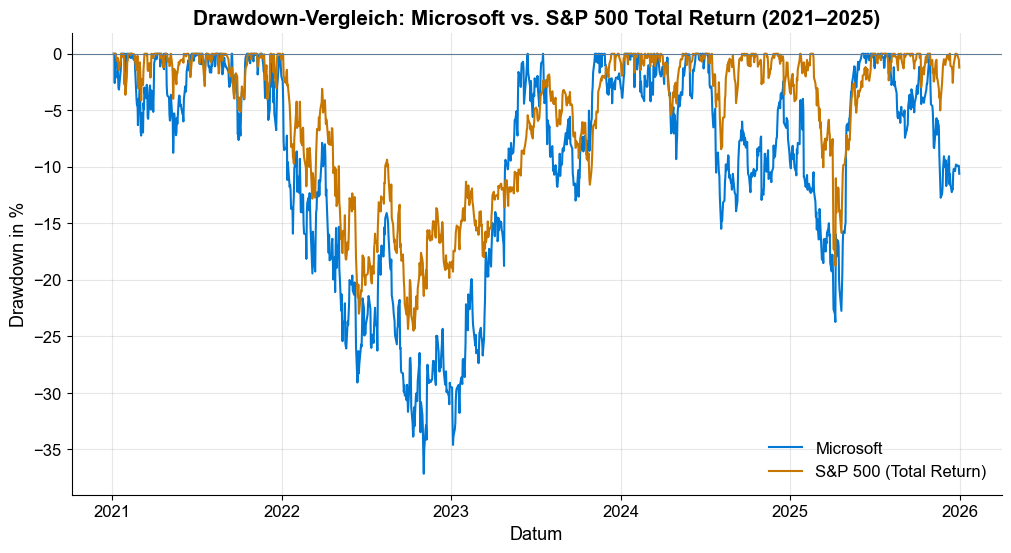

In [53]:
fig, ax = plt.subplots()
ax.plot(msft_drawdown.index, msft_drawdown * 100, color=FARBEN["msft"], label="Microsoft", linewidth=1.5)
ax.plot(sp500_drawdown.index, sp500_drawdown * 100, color=FARBEN["markt"], label="S&P 500 (Total Return)", linewidth=1.5)
ax.axhline(0, color=FARBEN["grau"], linewidth=0.8)
ax.set_title("Drawdown-Vergleich: Microsoft vs. S&P 500 Total Return (2021–2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Drawdown in %")
ax.legend(loc="lower right")
plt.show()

##### Risiko-Rendite-Vergleich

Die beiden Punkte stellen die annualisierte durchschnittliche Rendite der beiden Reihen gegen ihre annualisierte Volatilität. Damit lässt sich der Renditevorsprung von Microsoft zusammen mit dem höheren Schwankungsrisiko ablesen.

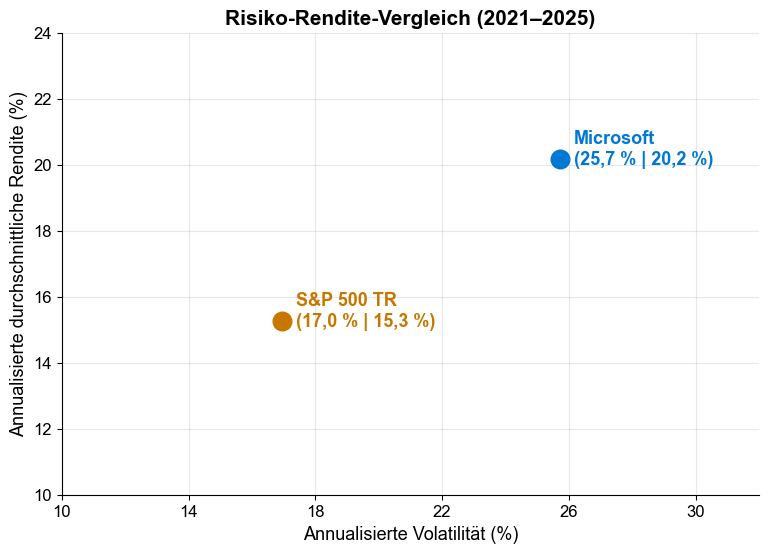

In [54]:
fig, ax = plt.subplots(figsize=(9, 6))
points = [("Microsoft", msft_annual_volatility, msft_annual_return, FARBEN["msft"]),
          ("S&P 500 TR", sp500_annual_volatility, sp500_annual_return, FARBEN["markt"])]
for name, vol, ret, color in points:
    ax.scatter(vol * 100, ret * 100, s=180, color=color, zorder=3)
    ax.annotate(f"{name}\n({de(vol * 100, 1)} % | {de(ret * 100, 1)} %)", xy=(vol * 100, ret * 100),
                xytext=(10, -4), textcoords="offset points", color=color, fontweight="bold")
ax.set_xlim(10, 32)
ax.set_ylim(10, 24)
ax.set_xticks(range(10, 33, 4))
ax.set_yticks(range(10, 25, 2))
ax.set_xlabel("Annualisierte Volatilität (%)")
ax.set_ylabel("Annualisierte durchschnittliche Rendite (%)")
ax.set_title("Risiko-Rendite-Vergleich (2021–2025)")
plt.show()

#### 6.6.10 Renditen nach Kalenderjahren

Die Gesamtkennzahlen können verdecken, in welchen Jahren der Renditevorsprung entstanden ist. Daher wird die Wertentwicklung je Kalenderjahr verglichen. Basis ist jeweils der letzte Handelstag des Vorjahres; für 2021 ist es der erste verfügbare Handelstag (04.01.2021), sodass 2021 ein nahezu vollständiges Jahr abbildet.

In [55]:
year_end = comparison.resample("YE").last()                # letzter Wert je Kalenderjahr
year_base = pd.concat([comparison.iloc[[0]], year_end])        # Startwert 04.01.2021 voranstellen
yearly_returns = year_base.pct_change().dropna() * 100
yearly_returns.index = yearly_returns.index.year
yearly_returns["Differenz (PP)"] = yearly_returns["Microsoft"] - yearly_returns["S&P 500 (Total Return)"]

print("Jahre mit Vorsprung von Microsoft:", list(yearly_returns.index[yearly_returns["Differenz (PP)"] > 0]))
yearly_returns.round(2)

Jahre mit Vorsprung von Microsoft: [2021, 2023]


,Microsoft,S&P 500 (Total Return),Differenz (PP)
Date,,,
2021,55.79,30.63,25.16
2022,-28.02,-18.11,-9.91
2023,58.19,26.29,31.90
2024,12.93,25.02,-12.09
2025,15.58,17.88,-2.30


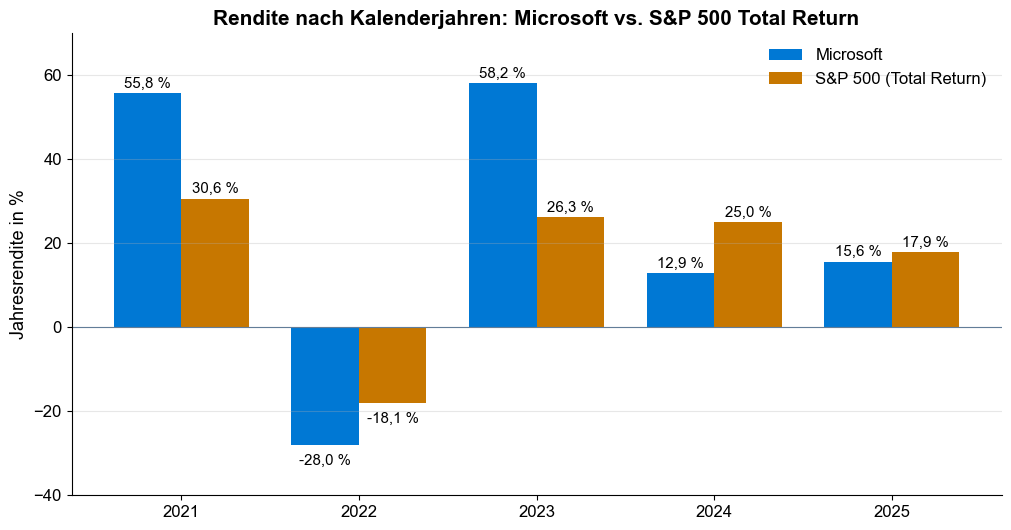

In [56]:
fig, ax = plt.subplots()
x = np.arange(len(yearly_returns))
width = 0.38
bars_msft = ax.bar(x - width / 2, yearly_returns["Microsoft"], width, color=FARBEN["msft"], label="Microsoft")
bars_sp = ax.bar(x + width / 2, yearly_returns["S&P 500 (Total Return)"], width, color=FARBEN["markt"], label="S&P 500 (Total Return)")
for bars in (bars_msft, bars_sp):
    for bar in bars:
        value = bar.get_height()
        ax.annotate(f"{de(value, 1)} %", xy=(bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 4 if value >= 0 else -14), textcoords="offset points", ha="center", fontsize="small")
ax.axhline(0, color=FARBEN["grau"], linewidth=0.8)
ax.set_xticks(x, [str(year) for year in yearly_returns.index])
ax.set_ylim(-40, 70)
ax.set_title("Rendite nach Kalenderjahren: Microsoft vs. S&P 500 Total Return")
ax.set_ylabel("Jahresrendite in %")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

Der Renditevorsprung von Microsoft entstand vor allem in **2021** (+25,2 Prozentpunkte) und **2023** (+31,9 Prozentpunkte). In **2022** fiel Microsoft deutlich stärker als der Markt, und in **2024** und **2025** lag der S&P 500 Total Return vorn. Microsoft schlug den Markt damit nur in **zwei von fünf** Kalenderjahren. Die höhere Gesamtrendite beruht also auf wenigen sehr starken Jahren und ist kein gleichmäßiger Vorsprung.

#### 6.6.11 Rollierendes Beta

Das Beta über den Gesamtzeitraum ist ein Durchschnittswert. Um zu prüfen, ob der Marktbezug stabil war, wird das Beta zusätzlich rollierend über jeweils **252 Handelstage** (ein Jahr) berechnet.

Höchstes rollierendes Beta: 1,40 am 09.10.2023
Niedrigstes rollierendes Beta: 0,91 am 23.12.2025
Rollierendes Beta am Ende des Zeitraums: 0,91


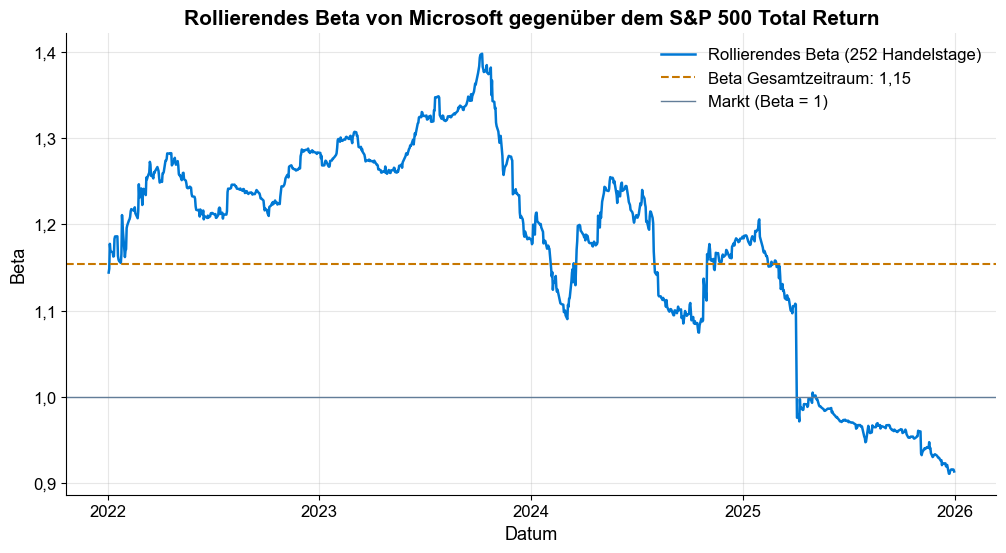

In [57]:
window = trading_days
rolling_beta = msft_returns.rolling(window).cov(market_returns) / market_returns.rolling(window).var()

print("Höchstes rollierendes Beta:", de(rolling_beta.max()), "am", rolling_beta.idxmax().strftime("%d.%m.%Y"))
print("Niedrigstes rollierendes Beta:", de(rolling_beta.min()), "am", rolling_beta.idxmin().strftime("%d.%m.%Y"))
print("Rollierendes Beta am Ende des Zeitraums:", de(rolling_beta.iloc[-1]))

fig, ax = plt.subplots()
ax.plot(rolling_beta.index, rolling_beta, color=FARBEN["msft"], linewidth=1.8, label="Rollierendes Beta (252 Handelstage)")
ax.axhline(beta_msft, color=FARBEN["markt"], linestyle="--", linewidth=1.5, label=f"Beta Gesamtzeitraum: {de(beta_msft)}")
ax.axhline(1, color=FARBEN["grau"], linewidth=1, label="Markt (Beta = 1)")
ax.set_title("Rollierendes Beta von Microsoft gegenüber dem S&P 500 Total Return")
ax.set_xlabel("Datum")
ax.set_ylabel("Beta")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: de(v, 1)))
ax.legend(loc="upper right")
plt.show()

Das rollierende Beta lag die meiste Zeit über 1 und erreichte im Oktober 2023 rund **1,40**. Bis Ende 2025 sank es auf rund **0,91**. Microsoft reagierte also nicht konstant stärker als der Markt; das Gesamtbeta von **1,15** ist ein Durchschnitt über Phasen mit sehr unterschiedlicher Marktsensitivität.

#### 6.6.12 Ergebnisvergleich

Die Vergleichstabelle und die Diagramme zeigen die Kennzahlen auf derselben Datenbasis. Microsoft erreicht die höhere **annualisierte durchschnittliche Rendite** und die höhere **CAGR**, weist jedoch zugleich die höhere **annualisierte Volatilität**, den höheren **Value at Risk** und den größeren Verlust im **Maximum Drawdown** auf. Sharpe Ratio und Sortino Ratio sind beim S&P 500 Total Return höher. Diese Rangfolge bleibt auch bei einem risikofreien Zinssatz von 0 % erhalten; das Ergebnis ist in dieser Hinsicht robust. Die Korrelation und das Beta beschreiben zusätzlich den Zusammenhang der täglichen Renditen mit dem Markt; sie ersetzen keine Risikokennzahl.

## 7. Fazit

In diesem Projekt wurde die historische Wertentwicklung der Microsoft-Aktie von 2021 bis 2025 mit Python untersucht. Analysiert wurden Kursverlauf und Trends, tägliche, kumulative und geometrische Renditen, die Verteilung der Renditen sowie mehrere Risikokennzahlen. Als Benchmark diente der S&P 500 Total Return Index.

### Ergebnisse der Microsoft-Analyse

Der bereinigte Microsoft-Schlusskurs stieg um rund **131,53 %**; das entspricht einer CAGR von rund **18,38 %** pro Jahr. Die arithmetisch annualisierte Rendite lag bei rund **20,17 %**, die annualisierte Volatilität bei rund **25,71 %**. Die Tagesrenditen sind nicht normalverteilt (Exzess-Kurtosis ≈ **3,23**). Der Maximum Drawdown von rund **−37,15 %** und ein VaR (95 %, 1 Tag) von rund **−2,64 %** zeigen, dass die positive langfristige Entwicklung mit erheblichen zwischenzeitlichen Verlusten verbunden war.

### Vergleich mit dem S&P 500

Microsoft erzielte die höhere Rendite (CAGR **18,38 %** gegenüber rund **14,84 %**). Gleichzeitig waren die annualisierte Volatilität (**25,71 %** gegenüber rund **16,96 %**) und der Maximum Drawdown (**−37,15 %** gegenüber rund **−24,49 %**) größer. Bei einem durchschnittlichen risikofreien Zinssatz von rund **3,22 %** (`^IRX`) lag die Sharpe Ratio von Microsoft bei rund **0,66**, die des Benchmarks bei rund **0,71**; die Sortino Ratio bestätigt dieses Bild (**0,97** gegenüber **1,02**). Mit einem Zinssatz von 0 % bleibt die Rangfolge gleich (**0,78** gegenüber **0,90**). Der Vorsprung entstand vor allem 2021 und 2023; in drei von fünf Kalenderjahren lag der Index vorn. Die täglichen Renditen korrelierten positiv (**r ≈ 0,76**), das Beta von rund **1,15** schwankte rollierend zwischen etwa **0,91** und **1,40**. Microsoft erzielte somit den höheren Ertrag, aber auf Basis dieser Kennzahlen kein besseres risikoadjustiertes Ergebnis.

### Kritische Reflexion

Die Ergebnisse beruhen auf historischen Yahoo-Finance-Daten. Nachträgliche Datenkorrekturen können einzelne Werte beim erneuten Abruf leicht verändern. Die bereinigte Microsoft-Kursreihe ist eine Näherung für eine Anlage mit berücksichtigten Ausschüttungen; eine konkrete Wiederanlagestrategie wurde nicht simuliert. Steuern, Transaktionskosten und Wechselkursrisiken für einen Euro-Anleger werden nicht berücksichtigt.

Die arithmetisch annualisierte Rendite überzeichnet das tatsächliche Wachstum; deshalb wurde die CAGR ergänzt. Der risikofreie Zinssatz wurde über `^IRX` abgebildet und das Ergebnis mit 0 % auf Robustheit geprüft. Volatilität beschreibt nur die Streuung der Renditen; wegen der nicht normalverteilten Renditen wurden VaR und CVaR ergänzt. Korrelation und Beta sind historische, vom Zeitraum abhängige Kennzahlen und durch die Indexzugehörigkeit von Microsoft teilweise mechanisch erhöht; sie belegen keine Kausalität. Die Vergangenheit erlaubt keine sichere Prognose für die künftige Entwicklung.

### Quellen (Literatur)

- Bodie, Z., Kane, A., & Marcus, A. J. (2021). *Investments* (12. Aufl.). McGraw-Hill.
- Hilpisch, Y. (2018). *Python for Finance* (2. Aufl.). O'Reilly.
- IU Internationale Hochschule. (2026). *Einführung in die Programmierung mit Python* (DLBDSIPWP01_D, Versionsnr. 001-2026-0615).
- Jarque, C. M., & Bera, A. K. (1980). Efficient tests for normality, homoscedasticity and serial independence of regression residuals. *Economics Letters, 6*(3), 255–259.
- Jorion, P. (2007). *Value at Risk* (3. Aufl.). McGraw-Hill.
- Sharpe, W. F. (1966). Mutual fund performance. *The Journal of Business, 39*(1), 119–138.
- Sortino, F. A., & van der Meer, R. (1991). Downside risk. *The Journal of Portfolio Management, 17*(4), 27–31.
- S&P Dow Jones Indices. (o. J.). *S&P 500*. https://www.spglobal.com/spdji/en/indices/equity/sp-500/